Calcolo degli hash percettivi per tutte le immagini...


100%|██████████| 931/931 [00:05<00:00, 185.10it/s]



Calcolo della matrice delle distanze tra gli hash...


100%|██████████| 931/931 [00:00<00:00, 937.71it/s] 



Sono state trovate 27 coppie di immagini molto simili (distanza < 5).

Esempio di coppie simili:

Coppia 1 - Distanza: 4.0
  Img 1: 0013
  Img 2: 0383


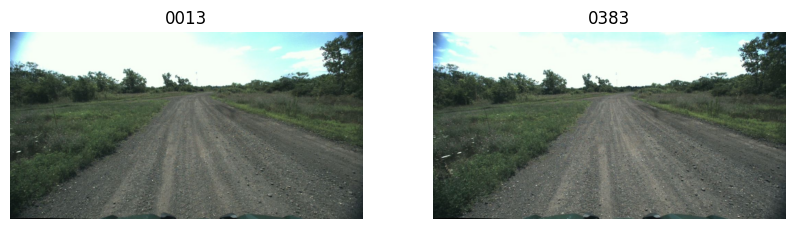


Coppia 2 - Distanza: 4.0
  Img 1: 0064
  Img 2: 0662


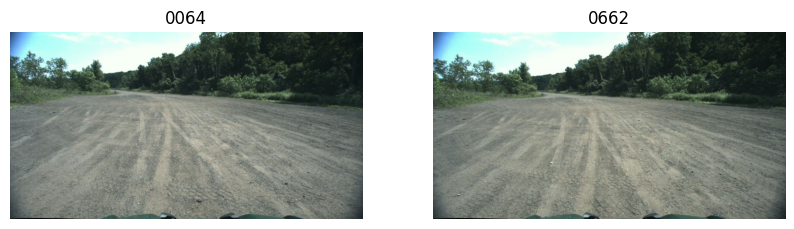


Coppia 3 - Distanza: 4.0
  Img 1: 0152
  Img 2: 1234


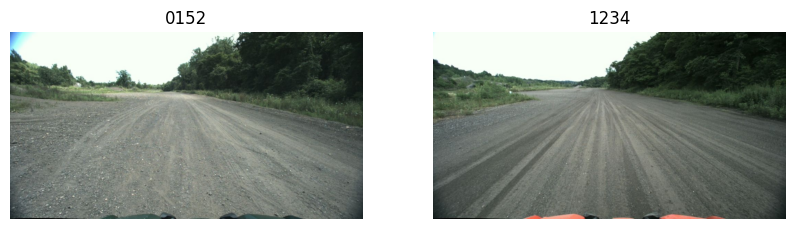


Coppia 4 - Distanza: 4.0
  Img 1: 0153
  Img 2: 0154


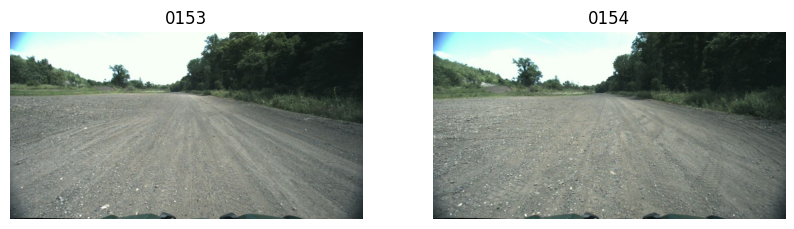

In [2]:
import imagehash
from PIL import Image
import os
import glob
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt

# Assicurati che DATASET_PATH sia definito correttamente
DATASET_PATH = "../../dataset/training/train" # Modifica se necessario

# 1. Calcola l'hash per ogni immagine
all_sample_dirs = sorted([d for d in glob.glob(os.path.join(DATASET_PATH, "*")) if os.path.isdir(d) and not os.path.basename(d).startswith('__')])

hashes = {}
print("Calcolo degli hash percettivi per tutte le immagini...")
for sample_dir in tqdm(all_sample_dirs):
    img_path = os.path.join(sample_dir, 'rgb.jpg')
    try:
        with Image.open(img_path) as img:
            # pHash è robusto a piccole variazioni e cambi di dimensione
            h = imagehash.phash(img)
            hashes[sample_dir] = h
    except FileNotFoundError:
        continue

# 2. Calcola la matrice delle distanze
# La distanza di Hamming tra due hash ci dice quanto sono diversi (0 = identici)
print("\nCalcolo della matrice delle distanze tra gli hash...")
sample_paths = list(hashes.keys())
n_samples = len(sample_paths)
distance_matrix = np.zeros((n_samples, n_samples))

for i in tqdm(range(n_samples)):
    for j in range(i, n_samples):
        dist = hashes[sample_paths[i]] - hashes[sample_paths[j]]
        distance_matrix[i, j] = dist
        distance_matrix[j, i] = dist

# 3. Analizza i risultati
# Troviamo le coppie di immagini più simili (distanza < soglia)
SIMILARITY_THRESHOLD = 5 # Soglia sperimentale: 0 è identico, < 5 è molto simile
similar_pairs = np.where((distance_matrix > 0) & (distance_matrix < SIMILARITY_THRESHOLD))

print(f"\nSono state trovate {len(similar_pairs[0]) // 2} coppie di immagini molto simili (distanza < {SIMILARITY_THRESHOLD}).")

# Visualizziamo qualche coppia per conferma
num_pairs_to_show = 5
print("\nEsempio di coppie simili:")
for i in range(min(num_pairs_to_show, len(similar_pairs[0]))):
    idx1 = similar_pairs[0][i]
    idx2 = similar_pairs[1][i]
    
    # Evitiamo di stampare la stessa coppia due volte
    if idx1 >= idx2:
        continue
        
    path1 = sample_paths[idx1]
    path2 = sample_paths[idx2]
    dist = distance_matrix[idx1, idx2]
    
    print(f"\nCoppia {i+1} - Distanza: {dist}")
    print(f"  Img 1: {os.path.basename(path1)}")
    print(f"  Img 2: {os.path.basename(path2)}")
    
    # Visualizzazione
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(Image.open(os.path.join(path1, 'rgb.jpg')))
    axes[0].set_title(os.path.basename(path1))
    axes[0].axis('off')
    axes[1].imshow(Image.open(os.path.join(path2, 'rgb.jpg')))
    axes[1].set_title(os.path.basename(path2))
    axes[1].axis('off')
    plt.show()